<a href="https://colab.research.google.com/github/keikezon/FIAP-IA-para-devs/blob/master/FIAP_Fase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install mne -q

In [7]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
arquivo_edf = "chb24_01.edf"
raw = mne.io.read_raw_edf(arquivo_edf, preload=True)
raw

Extracting EDF parameters from chb24_01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 921599  =      0.000 ...  3599.996 secs...


/tmp/ipykernel_861/2877399466.py:2: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(arquivo_edf, preload=True)


<RawEDF | chb24_01.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>

In [10]:
print(raw.info)
print(raw.ch_names)
print(f"Taxa de amostragen: {raw.info['sfreq']} Hz")

<Info | 8 non-empty values
 bads: []
 ch_names: FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3-P3, P3-O1, ...
 chs: 23 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2074-01-25 16:26:28 UTC
 nchan: 23
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: Surrogate>
>
['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
Taxa de amostragen: 256.0 Hz


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


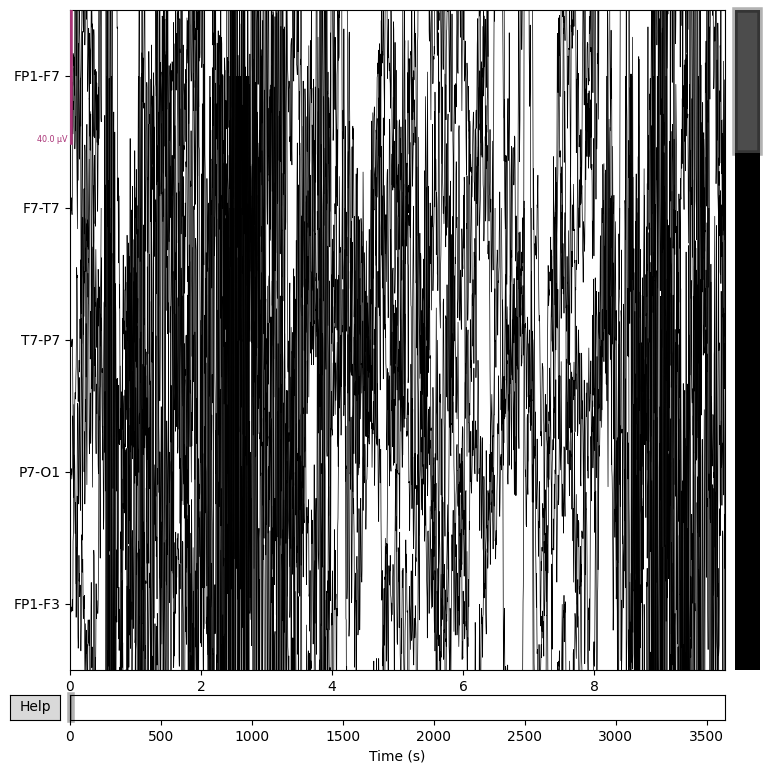

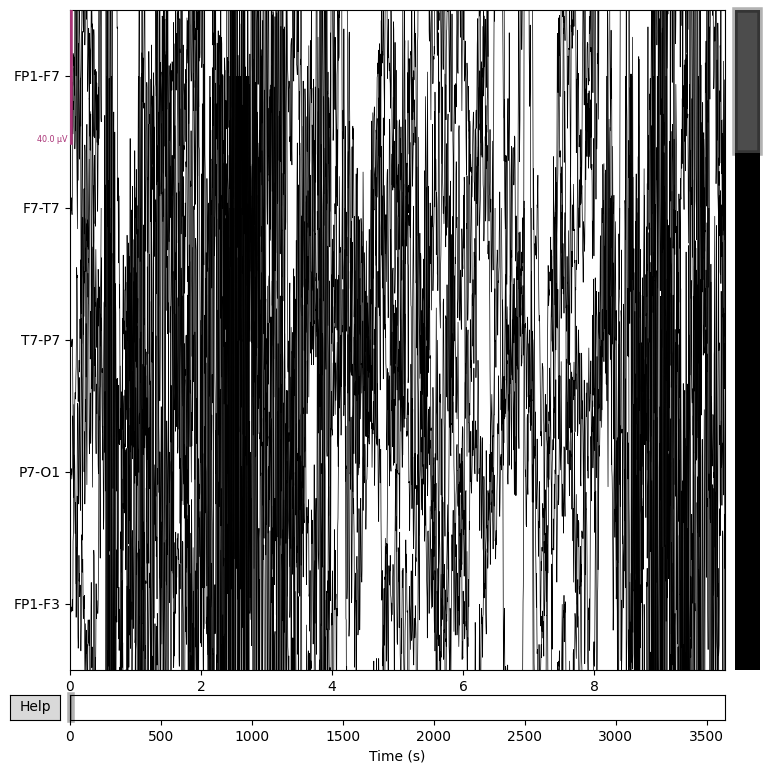

In [11]:
raw.plot(duration=10, n_channels=5)

In [12]:
data = raw.get_data()
data.shape

(23, 921600)

In [13]:
print("Números de canais: ", data.shape[0])
print("Números de amostras: ", data.shape[1])

Números de canais:  23
Números de amostras:  921600


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1691 samples (6.605 s)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


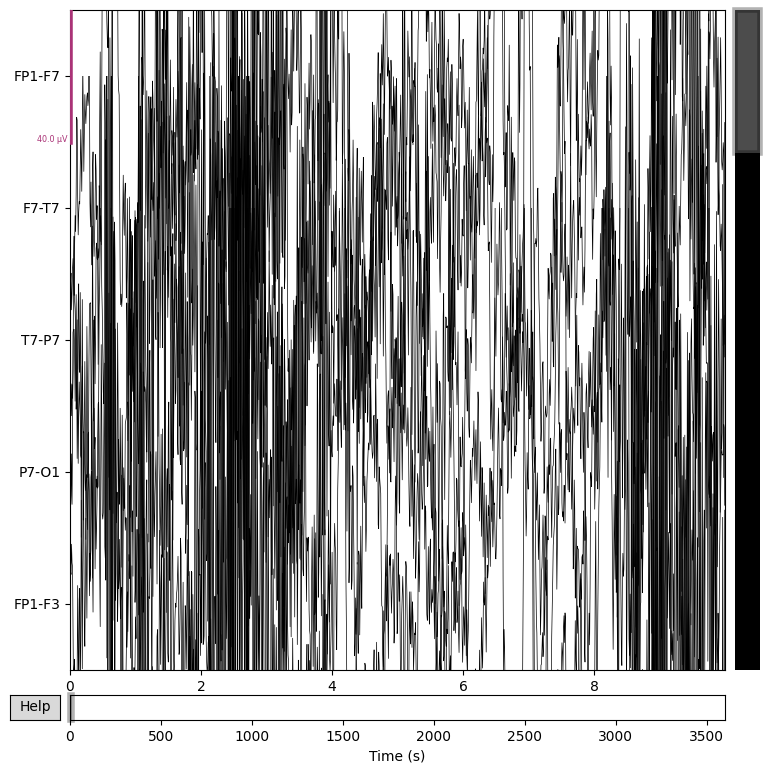

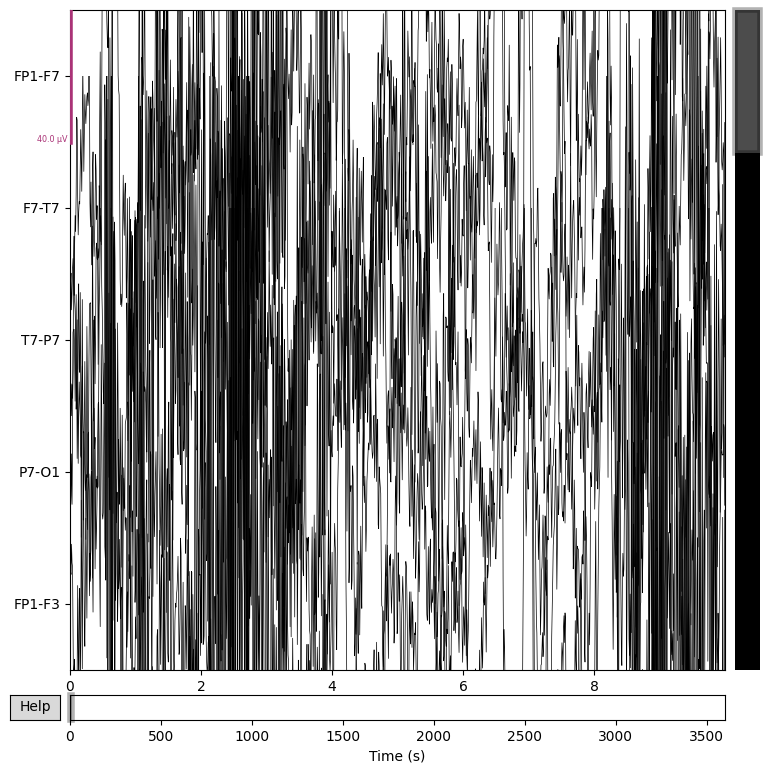

In [14]:
raw_filtrado = raw.copy().filter(0.5, 40)
raw_filtrado.plot(duration=10, n_channels=5)

In [15]:
data_filtrado = raw_filtrado.get_data()
data_filtrado.shape

(23, 921600)

In [16]:
with open("chb24-summary.txt", "r") as f:
  conteudo = f.readlines()

for linha in conteudo[:40]:
  print(linha.strip())

Data Sampling Rate: 256 Hz
*************************

Channels in EDF Files:
**********************
Channel 1: FP1-F7
Channel 2: F7-T7
Channel 3: T7-P7
Channel 4: P7-O1
Channel 5: FP1-F3
Channel 6: F3-C3
Channel 7: C3-P3
Channel 8: P3-O1
Channel 9: FP2-F4
Channel 10: F4-C4
Channel 11: C4-P4
Channel 12: P4-O2
Channel 13: FP2-F8
Channel 14: F8-T8
Channel 15: T8-P8
Channel 16: P8-O2
Channel 17: FZ-CZ
Channel 18: CZ-PZ
Channel 19: P7-T7
Channel 20: T7-FT9
Channel 21: FT9-FT10
Channel 22: FT10-T8
Channel 23: T8-P8

File Name: chb24_01.edf
Number of Seizures in File: 2
Seizure Start Time: 480 seconds
Seizure End Time: 505 seconds
Seizure Start Time: 2451 seconds
Seizure End Time: 2476 seconds

File Name: chb24_03.edf
Number of Seizures in File: 2
Seizure Start Time: 231 seconds
Seizure End Time: 260 seconds


In [17]:
seizure_intervals_sec = [
     (480, 505),
     (2451, 2476)
 ]

sfreq = raw.info["sfreq"]

In [18]:
canal_idx = 0
signal = data_filtrado[canal_idx]

In [19]:
time = np.arange(len(signal)) / sfreq

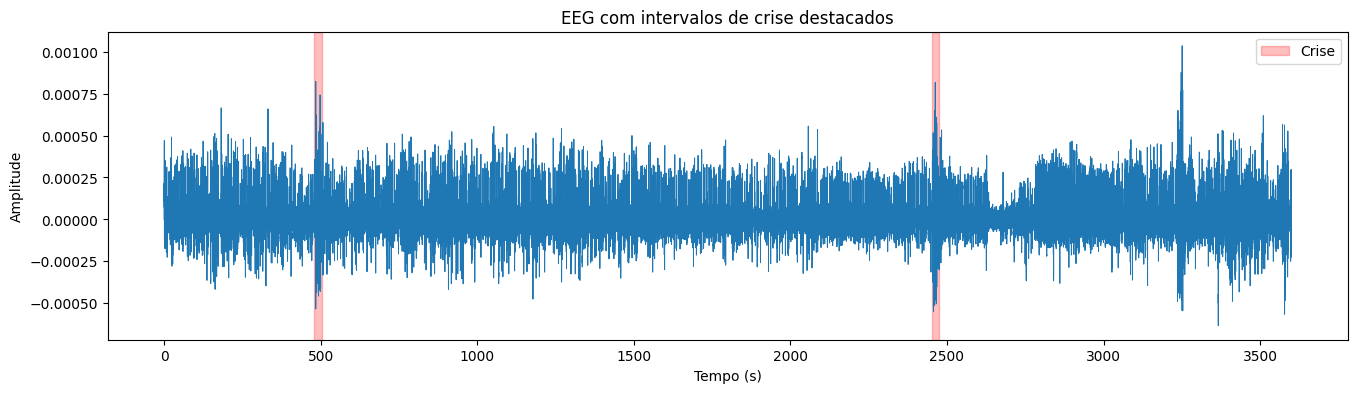

In [20]:
plt.figure(figsize=(16, 4))
plt.plot(time, signal, linewidth=0.7)

for i, (start, end) in enumerate(seizure_intervals_sec):
  plt.axvspan(start, end, color="red", alpha=0.25, label="Crise" if i==0 else None)

plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("EEG com intervalos de crise destacados")
plt.legend()
plt.show()

In [21]:
window_size = 256
step = 128

windows = []

for start in range(0, data_filtrado.shape[1] - window_size, step):
  segment = data_filtrado[:, start:start+window_size]
  windows.append(segment)

windows = np.array(windows)
windows.shape

(7198, 23, 256)

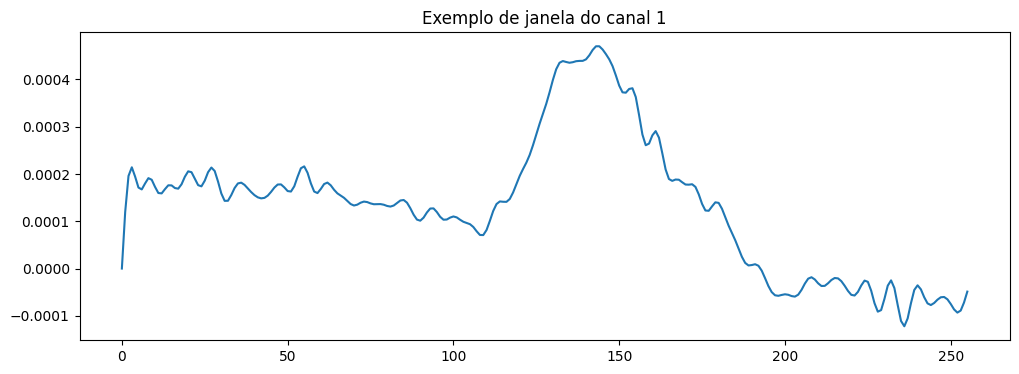

In [22]:
plt.figure(figsize=(12, 4))
plt.plot(windows[0, 0])
plt.title("Exemplo de janela do canal 1")
plt.show()

In [23]:
print("Quantidade de janelas: ", windows.shape[0])
print("Canais por janela: ", windows.shape[1])
print("Pontos por janela: ", windows.shape[2])

Quantidade de janelas:  7198
Canais por janela:  23
Pontos por janela:  256


In [25]:
features = []

for window in windows:
  feat = []
  feat.extend(window.mean(axis=1))
  feat.extend(window.std(axis=1))
  feat.extend(window.max(axis=1))
  feat.extend(window.min(axis=1))
  features.append(feat)

x = np.array(features)
x.shape

(7198, 92)

In [28]:
# lista onde vamos guardar o rótulo de cada janela
labels = []

# percorre o sinal da mesma forma que criamos as janelas
for start in range(0, data_filtrado.shape[1] - window_size, step):
  end = start + window_size # fim da janela

  # converte indice -> tempo (segundos)
  start_sec = start / sfreq
  end_sec = end / sfreq

  label = 0 # assume que é normal

  # verifica se a janela encosta em algum intervalo de crise
  for seizure_start, seizure_end in seizure_intervals_sec:
    overlap = (start_sec < seizure_end) and (end_sec > seizure_start)
    if(overlap):
      label = 1 # marca como crise
      break

  labels.append(label)

# transforma em array
y = np.array(labels)

# resumo
print("Janelas totais:", len(y))
print("Janelas com crise:", sum(y))
print("Janelas normais:", (y == 0).sum())

Janelas totais: 7198
Janelas com crise: 102
Janelas normais: 7096


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [36]:
# Modelo árvore de decisão
from sklearn.tree import DecisionTreeClassifier

modelo_arvore = DecisionTreeClassifier(random_state=42)
modelo_arvore.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [39]:
from sklearn.metrics import accuracy_score

# o modelo faz previsões em dados que ele nunca viu (teste)
y_pred = modelo_arvore.predict(X_test)

# comparando algumas previsões com o valor real
print("Comparação entre valor real e previsto:")
for i in range(10):
  print(f"Real: {y_test[i]}, Previsto: {y_pred[i]}")

# calculando a acurácia (quantos ele acertou no total)
accuracy = accuracy_score(y_test, y_pred)

print("Acurácia do modelo:", accuracy)

Comparação entre valor real e previsto:
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Real: 0, Previsto: 0
Acurácia do modelo: 0.9881944444444445


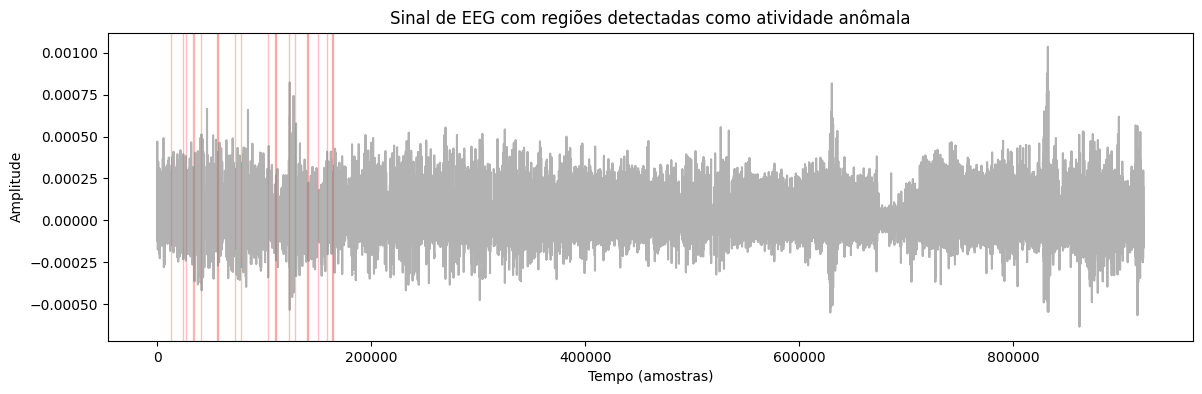

In [47]:
import matplotlib.pyplot as plt

# sinal de um canal para visualização
signal = data_filtrado[0]

plt.figure(figsize=(14, 4))
plt.plot(signal, color='gray', alpha=0.6)

# desenhando janelas classificadas
for i, pred in enumerate(y_pred):
  start = i * step
  end = start + window_size
  if(pred == 1): # classe anômala
    plt.axvspan(start, end, color='red', alpha=0.25)

plt.title("Sinal de EEG com regiões detectadas como atividade anômala")
plt.xlabel("Tempo (amostras)")
plt.ylabel("Amplitude")
plt.show()

In [48]:
amostra = X_test[0].reshape(1, -1)
pred = modelo_arvore.predict(amostra)[0]

print("Predição da amostra:", pred)


Predição da amostra: 0
